# Pix2Pix is a Conditional Generative Adversarial Network (cGAN) designed for image-to-image translation—turning sketches into photos, day into night, or black-and-white into color.

#*The Architecture:*
In a standard GAN, the Generator creates images from random noise.

In Pix2Pix, the Generator is "conditioned" on an input image.

###Generator (U-Net):

It takes the source image (e.g., a sketch), compresses it down to capture the essence, and then expands it back into the target image (e.g., a photo). The "U-Net" style uses skip connections to ensure fine details from the sketch aren't lost during compression.

###Discriminator (PatchGAN):

Instead of looking at the whole image and saying "this is fake," it looks at small $N \times N$ patches. This forces the model to focus on high-frequency details like texture and style.

In [1]:
import torch
import torch.nn as nn
from matplotlib import pyplot as plt
import numpy as np

# Standard hyper-parameters
OUTPUT_CHANNELS = 3
LAMBDA = 100 # Weight for the L1 loss (Mean Absolute Error)

In [2]:
import torch
import torch.nn as nn

class Block(nn.Module):
    def __init__(self, in_channels, out_channels, down=True, act="relu", use_dropout=False):
        super(Block, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 4, 2, 1, bias=False, padding_mode="reflect")
            if down
            else nn.ConvTranspose2d(in_channels, out_channels, 4, 2, 1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU() if act == "relu" else nn.LeakyReLU(0.2),
        )
        self.use_dropout = use_dropout
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.conv(x)
        return self.dropout(x) if self.use_dropout else x

In [3]:
class Generator(nn.Module):
    def __init__(self, in_channels=3, features=64):
        super().__init__()

        # Encoder (Downsampling)
        self.initial_down = nn.Sequential(
            nn.Conv2d(in_channels, features, 4, 2, 1, padding_mode="reflect"),
            nn.LeakyReLU(0.2),
        ) # 128x128

        self.down1 = Block(features, features * 2, down=True, act="leaky") # 64x64
        self.down2 = Block(features * 2, features * 4, down=True, act="leaky") # 32x32
        self.down3 = Block(features * 4, features * 8, down=True, act="leaky") # 16x16
        self.down4 = Block(features * 8, features * 8, down=True, act="leaky") # 8x8
        self.down5 = Block(features * 8, features * 8, down=True, act="leaky") # 4x4
        self.down6 = Block(features * 8, features * 8, down=True, act="leaky") # 2x2

        # Bottleneck
        self.bottleneck = nn.Sequential(
            nn.Conv2d(features * 8, features * 8, 4, 2, 1),
            nn.ReLU()
        ) # 1x1

        # Decoder (Upsampling) with Skip Connections
        self.up1 = Block(features * 8, features * 8, down=False, act="relu", use_dropout=True)
        self.up2 = Block(features * 8 * 2, features * 8, down=False, act="relu", use_dropout=True)
        self.up3 = Block(features * 8 * 2, features * 8, down=False, act="relu", use_dropout=True)
        self.up4 = Block(features * 8 * 2, features * 8, down=False, act="relu")
        self.up5 = Block(features * 8 * 2, features * 4, down=False, act="relu")
        self.up6 = Block(features * 4 * 2, features * 2, down=False, act="relu")
        self.up7 = Block(features * 2 * 2, features, down=False, act="relu")

        self.final_up = nn.Sequential(
            nn.ConvTranspose2d(features * 2, in_channels, kernel_size=4, stride=2, padding=1),
            nn.Tanh(), # Normalizes output to [-1, 1]
        )

    def forward(self, x):
        # Encoder passes
        d1 = self.initial_down(x)
        d2 = self.down1(d1)
        d3 = self.down2(d2)
        d4 = self.down3(d3)
        d5 = self.down4(d4)
        d6 = self.down5(d5)
        d7 = self.down6(d6)

        # Bottleneck
        bn = self.bottleneck(d7)

        # Decoder passes with skip connections (concatenation)
        # Note: torch.cat happens on dimension 1 (channels)
        u1 = self.up1(bn)
        u2 = self.up2(torch.cat([u1, d7], dim=1))
        u3 = self.up3(torch.cat([u2, d6], dim=1))
        u4 = self.up4(torch.cat([u3, d5], dim=1))
        u5 = self.up5(torch.cat([u4, d4], dim=1))
        u6 = self.up6(torch.cat([u5, d3], dim=1))
        u7 = self.up7(torch.cat([u6, d2], dim=1))

        return self.final_up(torch.cat([u7, d1], dim=1))


def test_generator():
    x = torch.randn((1, 3, 256, 256))
    gen = Generator(in_channels=3, features=64)
    preds = gen(x)
    print(f"Input shape: {x.shape}")
    print(f"Output shape: {preds.shape}") # Should be identical to input

test_generator()

Input shape: torch.Size([1, 3, 256, 256])
Output shape: torch.Size([1, 3, 256, 256])


In [4]:
#The PatchGAN DiscriminatorInstead of a single scalar output (0 or 1),
#the PatchGAN outputs a grid (e.g., $30 \times 30$).
#Each pixel in that grid represents a patch of the original image,
#telling the model if that specific "texture" looks real.

import torch
import torch.nn as nn

class CNNBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=2):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 4, stride, 1, bias=False, padding_mode="reflect"),
            nn.BatchNorm2d(out_channels),
            nn.LeakyReLU(0.2),
        )

    def forward(self, x):
        return self.conv(x)

class Discriminator(nn.Module):
    def __init__(self, in_channels=3, features=[64, 128, 256, 512]):
        super().__init__()

        # Initial layer: No BatchNorm according to the original paper
        self.initial = nn.Sequential(
            nn.Conv2d(in_channels * 2, features[0], kernel_size=4, stride=2, padding=1, padding_mode="reflect"),
            nn.LeakyReLU(0.2),
        )

        layers = []
        in_channels_idx = features[0]
        for feature in features[1:]:
            # The last feature block usually uses stride=1 to maintain resolution for the final patch grid
            layers.append(
                CNNBlock(in_channels_idx, feature, stride=1 if feature == features[-1] else 2),
            )
            in_channels_idx = feature

        self.model = nn.Sequential(*layers)

        # Final layer: Outputs the 1-channel prediction map
        self.final = nn.Conv2d(in_channels_idx, 1, kernel_size=4, stride=1, padding=1, padding_mode="reflect")

    def forward(self, x, y):
        # Concatenate input image (x) and target/generated image (y)
        x = torch.cat([x, y], dim=1)
        x = self.initial(x)
        x = self.model(x)
        return self.final(x)


def test_generator():
    x = torch.randn((1, 3, 256, 256))
    disc = Discriminator(in_channels=3)
    preds = disc(x, x)
    print(f"Input shape: {x.shape}")
    print(f"Output shape: {preds.shape}") # Should be identical to input

test_generator()

Input shape: torch.Size([1, 3, 256, 256])
Output shape: torch.Size([1, 1, 30, 30])


In [5]:
!wget -N http://efrosgans.eecs.berkeley.edu/pix2pix/datasets/facades.tar.gz
!tar -xf facades.tar.gz

--2026-04-16 11:20:42--  http://efrosgans.eecs.berkeley.edu/pix2pix/datasets/facades.tar.gz
Resolving efrosgans.eecs.berkeley.edu (efrosgans.eecs.berkeley.edu)... 128.32.244.190
Connecting to efrosgans.eecs.berkeley.edu (efrosgans.eecs.berkeley.edu)|128.32.244.190|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 30168306 (29M) [application/x-gzip]
Saving to: ‘facades.tar.gz’

facades.tar.gz      100%[===================>]  28.77M   653KB/s    in 73s     

2026-04-16 11:21:55 (401 KB/s) - ‘facades.tar.gz’ saved [30168306/30168306]



In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms as T
from torchvision.utils import save_image
import os
from PIL import Image
from tqdm import tqdm

# --- CONFIGURATION ---
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
LEARNING_RATE = 2e-4
BATCH_SIZE = 16
IMAGE_SIZE = 256
CHANNELS_IMG = 3
L1_LAMBDA = 100
NUM_EPOCHS = 400

# --- DATASET ---
class FacadesDataset(Dataset):
    def __init__(self, root_dir):
        self.root_dir = root_dir
        self.list_files = os.listdir(self.root_dir)

    def __len__(self):
        return len(self.list_files)

    def __getitem__(self, index):
        img_path = os.path.join(self.root_dir, self.list_files[index])
        image = Image.open(img_path).convert("RGB")
        image = T.functional.to_tensor(image)

        # Facades images are 512x256, split into two 256x256
        c, h, w = image.shape
        target_image = image[:, :, :w//2]
        input_image = image[:, :, w//2:]

        transform = T.Compose([
            T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
            T.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
        ])
        return transform(input_image), transform(target_image)

# --- TRAINING LOOP ---
def train_fn(disc, gen, loader, opt_disc, opt_gen, l1_loss, bce, g_scaler, d_scaler, epoch):
    loop = tqdm(loader, leave=True)

    # Set the description to show the current epoch
    loop.set_description(f"Epoch [{epoch}/{NUM_EPOCHS}]")

    for idx, (x, y) in enumerate(loop):
        x, y = x.to(DEVICE), y.to(DEVICE)

        # Train Discriminator
        #autocast: In	Forward Pass maintains
        #	Speed & Memory - Decides which ops use float16 vs float32.
        with torch.cuda.amp.autocast():
            y_fake = gen(x)
            D_real = disc(x, y)
            D_fake = disc(x, y_fake.detach())
            D_real_loss = bce(D_real, torch.ones_like(D_real))
            D_fake_loss = bce(D_fake, torch.zeros_like(D_fake))
            D_loss = (D_real_loss + D_fake_loss) / 2

        disc.zero_grad()
        d_scaler.scale(D_loss).backward()
        d_scaler.step(opt_disc)
        d_scaler.update()

        # Train Generator
        with torch.cuda.amp.autocast():
            D_fake = disc(x, y_fake)
            G_fake_loss = bce(D_fake, torch.ones_like(D_fake))
            L1 = l1_loss(y_fake, y) * L1_LAMBDA
            G_loss = G_fake_loss + L1

        gen.zero_grad()
        g_scaler.scale(G_loss).backward()
        g_scaler.step(opt_gen)
        g_scaler.update()

        loop.set_postfix(D_loss=D_loss.item(), G_loss=G_loss.item())

# --- EXECUTION ---
def main():
    gen = Generator(in_channels=3).to(DEVICE)
    disc = Discriminator(in_channels=3).to(DEVICE)
    opt_gen = optim.Adam(gen.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999))
    opt_disc = optim.Adam(disc.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999))
    BCE = nn.BCEWithLogitsLoss()
    L1_LOSS = nn.L1Loss()

    train_dataset = FacadesDataset(root_dir="facades/train/")
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

    #torch.cuda.amp.GradScaler() and torch.cuda.amp.autocast()
    #are the two core components of Automatic Mixed Precision (AMP),
    #used to speed up training and reduce memory usage
    #while maintaining model accuracy.

    #GradScaler: In	Backward Pass maintains
    #	Stability - Prevents small gradients from becoming zero.
    g_scaler = torch.cuda.amp.GradScaler()
    d_scaler = torch.cuda.amp.GradScaler()

    for epoch in range(NUM_EPOCHS):
        # CHANGE 3: Pass 'epoch' at the end of the function call
        train_fn(disc, gen, train_loader, opt_disc, opt_gen, L1_LOSS, BCE, g_scaler, d_scaler, epoch)

        # Save a sample to check progress
        if epoch % 5 == 0:
            torch.save(gen.state_dict(), f"gen_epoch_{epoch}.pth")

if __name__ == "__main__":
    main()

/tmp/ipykernel_890/1791053337.py:104: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  g_scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_890/1791053337.py:105: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  d_scaler = torch.cuda.amp.GradScaler()
Epoch [0/400]:   0%|          | 0/25 [00:00<?, ?it/s]/tmp/ipykernel_890/1791053337.py:58: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_890/1791053337.py:72: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch [399/400]: 100%|██████████| 25/25 [00:06<00:00,  4.00it/s, D_loss=1.17, G_loss=9.35]


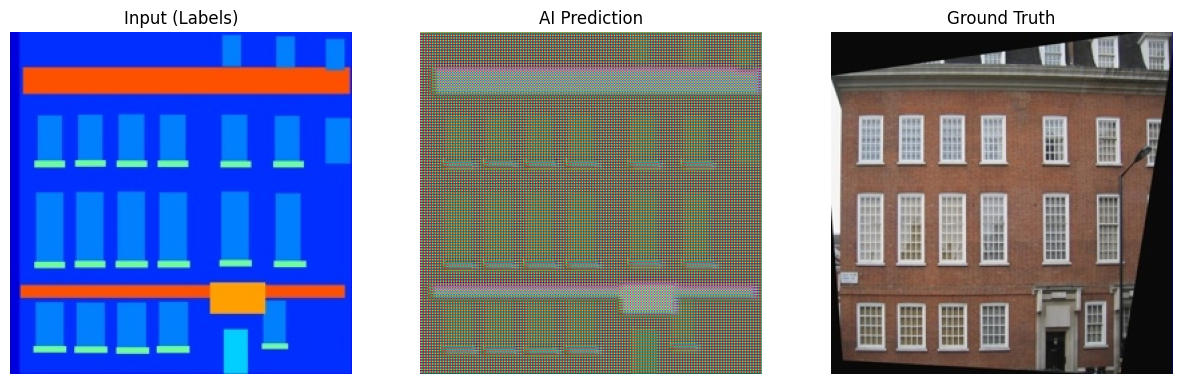

In [7]:
import matplotlib.pyplot as plt

def test_and_visualize(gen, dataset, device, index=0):
    """
    Takes a trained generator and a dataset, runs one image through,
    and plots the comparison.
    """
    gen.eval() # CRITICAL: Sets BatchNorm to use global statistics

    # Get a sample from the dataset
    input_img, target_img = dataset[index]

    # Add batch dimension and move to GPU
    input_batch = input_img.unsqueeze(0).to(device)

    with torch.no_grad():
        # The AI creates the image here
        prediction = gen(input_batch)

    # Move back to CPU and remove batch dimension
    prediction = prediction.cpu().squeeze(0)

    # Un-normalize from [-1, 1] to [0, 1] for matplotlib
    def unnorm(img):
        return img * 0.5 + 0.5

    # Prepare for plotting (C, H, W) -> (H, W, C)
    input_display = unnorm(input_img).permute(1, 2, 0)
    pred_display = unnorm(prediction).permute(1, 2, 0)
    target_display = unnorm(target_img).permute(1, 2, 0)

    # Create the plot
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(input_display)
    plt.title("Input (Labels)")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(pred_display)
    plt.title("AI Prediction")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(target_display)
    plt.title("Ground Truth")
    plt.axis("off")

    plt.show()

# 1. Load the test dataset
test_dataset = FacadesDataset(root_dir="facades/test/")
gen = Generator(in_channels=3).to(DEVICE)
# 2. Run the test on the 5th image in the folder
test_and_visualize(gen, test_dataset, DEVICE, index=5)

Testing Image 0:


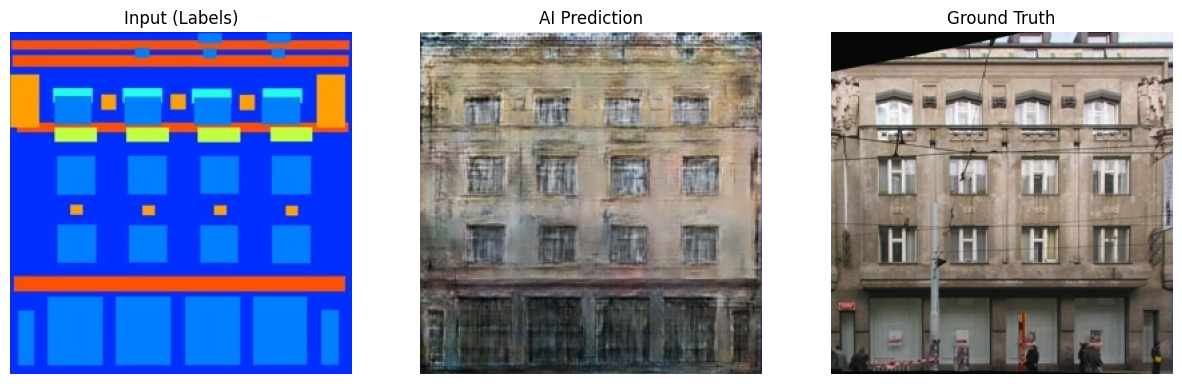

Testing Image 5:


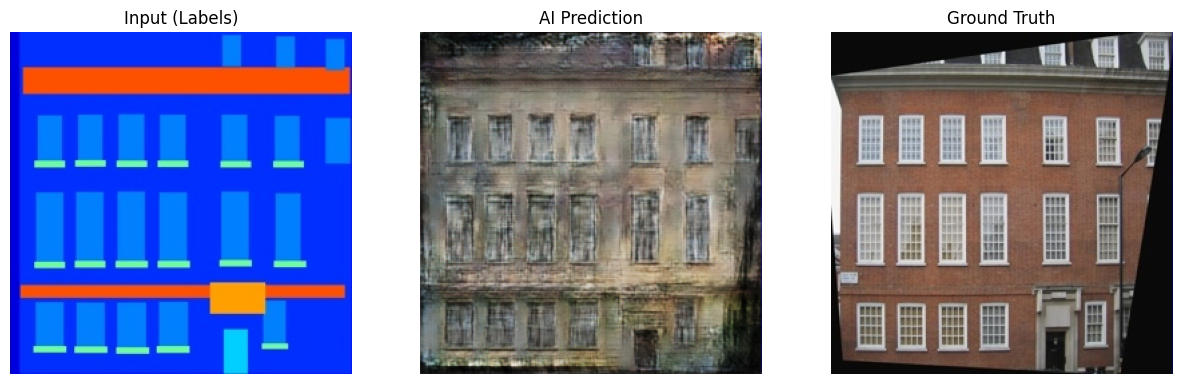

In [8]:
# 1. Re-initialize the model structure
final_gen = Generator(in_channels=3).to(DEVICE)

# 2. Load the trained weights from your latest checkpoint
# (Check your folder to see if it saved 195 or 199 as the last one)
final_gen.load_state_dict(torch.load("gen_epoch_195.pth", map_location=DEVICE))

# 3. Load the test dataset
test_dataset = FacadesDataset(root_dir="facades/test/")

# 4. Visualize a few different examples!
print("Testing Image 0:")
test_and_visualize(final_gen, test_dataset, DEVICE, index=0)

print("Testing Image 5:")
test_and_visualize(final_gen, test_dataset, DEVICE, index=5)

In [9]:
import matplotlib.pyplot as plt
import random
import torch

def test_and_visualize_multiple(gen, dataset, device, num_images=3):
    """
    Takes a trained generator and a dataset, runs multiple images through,
    and plots the comparisons in a grid.
    """
    gen.eval() # CRITICAL: Sets BatchNorm to use global statistics

    # Create a figure with 'num_images' rows and 3 columns
    fig, axes = plt.subplots(num_images, 3, figsize=(15, 5 * num_images))

    # Handle the edge case where num_images is 1 to keep array indexing consistent
    if num_images == 1:
        axes = [axes]

    # Get random indices to see a variety of buildings
    indices = random.sample(range(len(dataset)), num_images)

    for i, idx in enumerate(indices):
        # Get a sample from the dataset
        input_img, target_img = dataset[idx]

        # Add batch dimension and move to GPU
        input_batch = input_img.unsqueeze(0).to(device)

        with torch.no_grad():
            # The AI creates the image here
            prediction = gen(input_batch)

        # Move back to CPU and remove batch dimension
        prediction = prediction.cpu().squeeze(0)

        # Un-normalize from [-1, 1] to [0, 1] for matplotlib
        def unnorm(img):
            return img * 0.5 + 0.5

        # Prepare for plotting (C, H, W) -> (H, W, C)
        input_display = unnorm(input_img).permute(1, 2, 0)
        pred_display = unnorm(prediction).permute(1, 2, 0)
        target_display = unnorm(target_img).permute(1, 2, 0)

        # Plot Input (Labels)
        axes[i, 0].imshow(input_display)
        if i == 0: axes[i, 0].set_title("Input (Labels)", fontsize=16)
        axes[i, 0].axis("off")

        # Plot AI Prediction
        axes[i, 1].imshow(pred_display)
        if i == 0: axes[i, 1].set_title("AI Prediction", fontsize=16)
        axes[i, 1].axis("off")

        # Plot Ground Truth
        axes[i, 2].imshow(target_display)
        if i == 0: axes[i, 2].set_title("Ground Truth", fontsize=16)
        axes[i, 2].axis("off")

    # Adjust layout so titles and images don't overlap
    plt.tight_layout()
    plt.show()

# --- EXECUTION ---
# Assuming you just loaded final_gen as discussed previously
# test_dataset = FacadesDataset(root_dir="facades/test/")

print("Generating 4 random building translations...")
test_and_visualize_multiple(final_gen, test_dataset, DEVICE, num_images=10)

Output hidden; open in https://colab.research.google.com to view.